# Education and Fertility

How are education and fertility associated across historical regions?

Data: [datasets/swiss](https://vincentarelbundock.github.io/Rdatasets/doc/datasets/swiss.html)

This notebook performs a descriptive analysis on a real historical dataset. Source limitations: Ecological 1888 Swiss data; correlation does not establish individual behaviour or causation.

In [1]:
from pathlib import Path
from analysis import run
result = run(Path.cwd())
result["manifest"]

Out[0]: 
{'project': 'Education and Fertility',
 'executed_utc': '2026-11-21T10:14:12.309831+00:00',
 'source': 'https://vincentarelbundock.github.io/Rdatasets/csv/datasets/swiss.csv',
 'documentation': 'https://vincentarelbundock.github.io/Rdatasets/doc/datasets/swiss.html',
 'sha256': 'e9ee520d190a6586bb3072d5b4cace46930ce3eb3c85ba6d70fc2afa1e37dae8',
 'raw_rows': 47,
 'analysis_rows': 47,
 'excluded_rows': 0,
 'exact_duplicate_rows': 0,
 'duplicates_policy': 'Retained; duplicate values do not necessarily mean duplicate entities.',
 'python': '3.12.14',
 'pandas': '2.2.3',
 'numpy': '2.3.5',
 'matplotlib': '3.10.8',
 'pearson': -0.6637888570350693,
 'spearman': -0.4432576903609882}


## Data quality
Missing required variables are excluded, not silently imputed. Repeated rows are preserved; review the source observation grain.

In [2]:
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv("outputs/quality_audit.csv"))

,column,dtype,missing,missing_pct,distinct
0,rownames,object,0,0.0,47
1,Fertility,float64,0,0.0,46
2,Agriculture,float64,0,0.0,47
3,Examination,int64,0,0.0,22
4,Education,int64,0,0.0,19
5,Catholic,float64,0,0.0,46
6,Infant.Mortality,float64,0,0.0,37


## SQL and analysis
Complete-pair scatter plot of Education and Fertility, with Pearson and Spearman correlations. No regression adjustment or causal claim.

In [3]:
print(Path("analysis.sql").read_text())
display(result["table"].head(30))
print(result["finding"])

SELECT "Education" AS predictor, "Fertility" AS outcome FROM observations ORDER BY "Education";

Among 47 complete observations, Pearson r = -0.664 and Spearman rho = -0.443.


,predictor,outcome
0,1,72.5
1,2,68.3
2,2,75.5
3,2,77.3
4,3,65.0
5,3,72.0
6,3,79.4
7,3,92.2
8,5,92.5
9,5,61.7


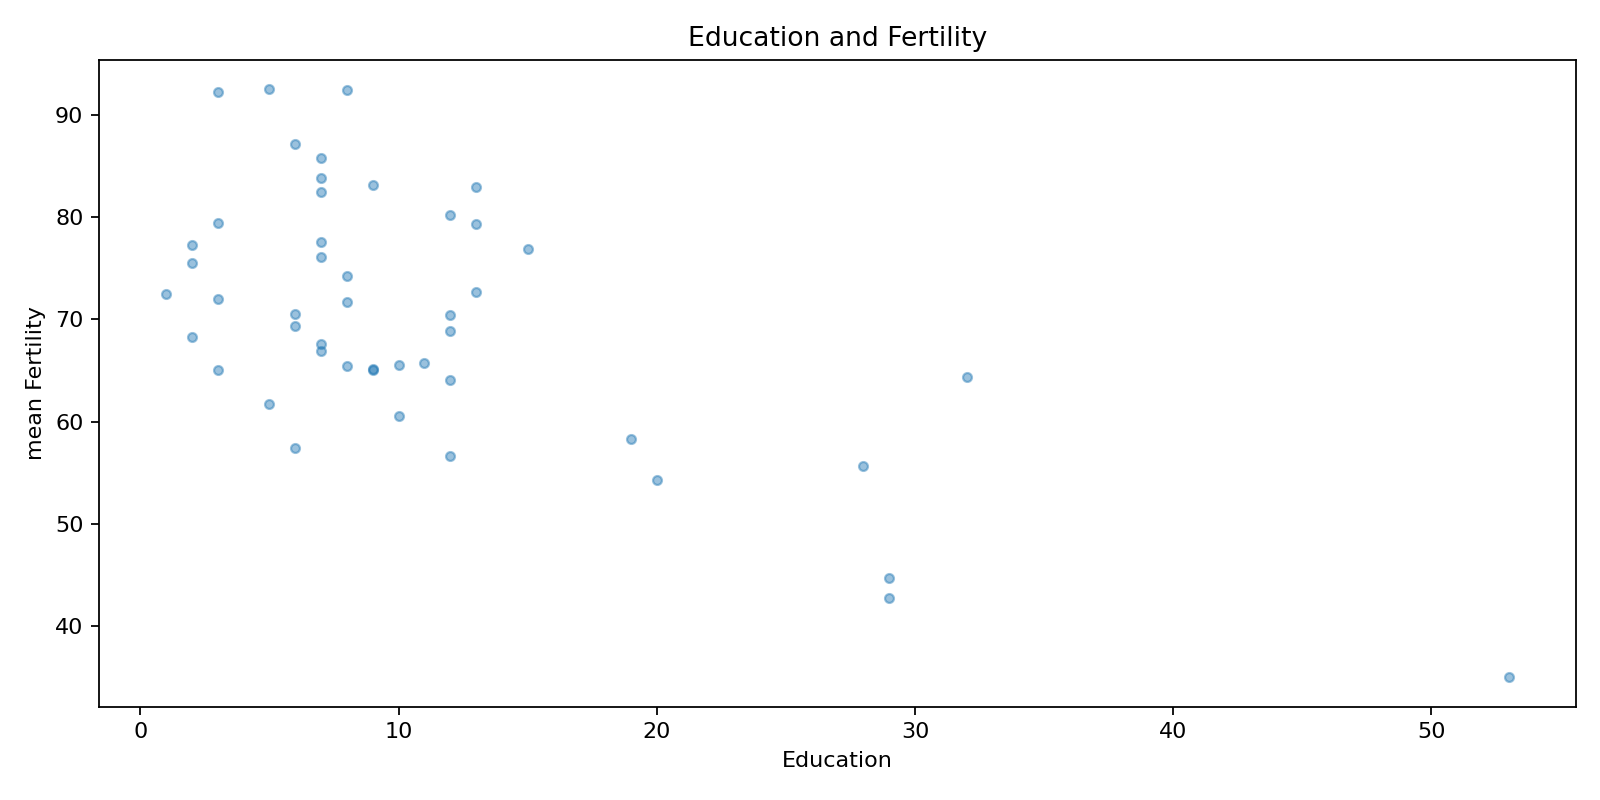

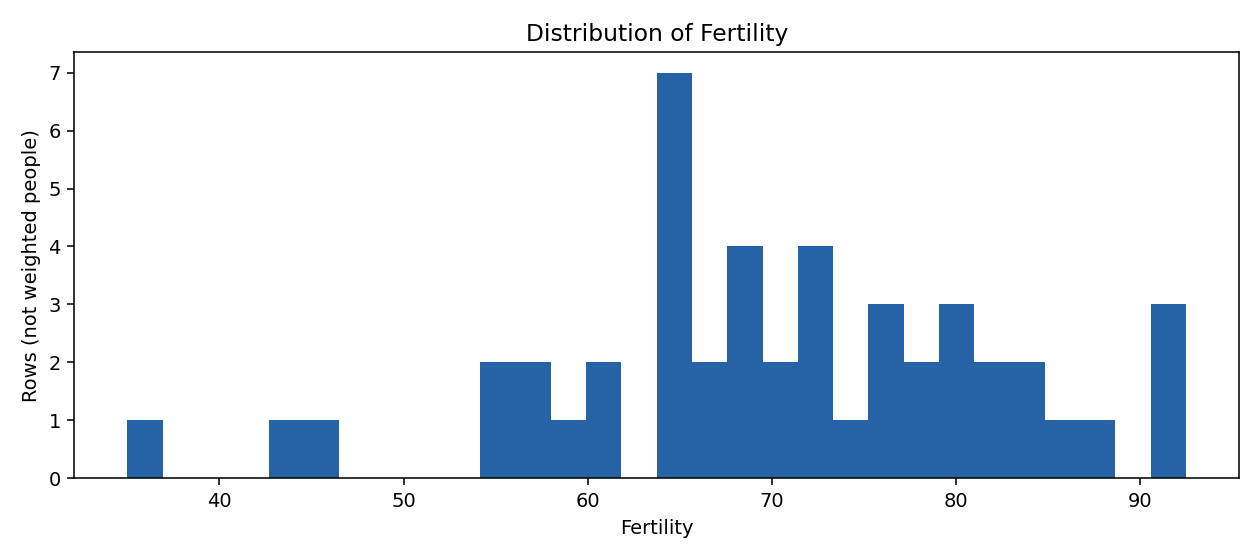

In [4]:
display(Image(filename="outputs/main_chart.png"))
display(Image(filename="outputs/distribution.png"))

## Interpretation
Ecological 1888 Swiss data; correlation does not establish individual behaviour or causation.

**Next action:** Identify confounding and avoid policy extrapolation.

Read outputs/REPORT.md for executed findings. This project does not establish causation or a production decision rule.